In [14]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

# 参数设置
N = 100  # 总节点数
D_ratio = 0.6  # 目的地节点比例
R_ratio = 1 - D_ratio  # 居住节点比例
R_count = int(R_ratio * N)  # 居住节点数
D_count = N - R_count  # 目的地节点数
P = 1000  # 总人口
beta = 0.3  # 感染率
mu = 0.1  # 恢复率
p = 0.1  # 移动概率
steps = 200  # 模拟时间步数

# 初始化网络
G = nx.watts_strogatz_graph(N, 4, 0.1)
W = nx.adjacency_matrix(G).todense()

# 随机分配人口到居住节点
n = np.zeros(N)
for i in range(R_count):
    n[i] = P / R_count

# 初始感染
rho = np.zeros(N)
# 从范围对象中随机选择 R_count 的 5% 个不重复元素。
initial_infected = random.sample(range(R_count), int(0.05 * R_count))
for i in initial_infected:
    rho[i] = 0.1

In [15]:
print("R_count:", R_count)
print("D_count:", D_count)
print("n[i]:",n)
print("initial_infected:", initial_infected)

rho = [1, 2, 3, 4, 5]
result = np.sum([1 * 4 * rho[j] for j in range(5)])
result

[1 * 4 * rho[j] for j in range(5)]

R_count: 40
D_count: 60
n[i]: [25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25.
 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25. 25.
 25. 25. 25. 25.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
initial_infected: [19, 33]


[4, 8, 12, 16, 20]

In [21]:
n = np.random.randint(50, 150, size=N)  # 每个节点的初始人口
  
n

array([ 79, 115, 125,  90,  80, 138, 113, 106, 116, 101, 110,  68, 102,
        65,  56,  61, 103, 131,  52,  82,  74,  83, 120,  91,  94, 129,
        64, 147, 140,  90,  71, 130,  66,  66,  72, 143, 118,  84, 114,
       147, 140,  65,  89, 104,  83, 105, 125, 100,  53, 138,  87, 140,
       110, 136,  53,  91, 113,  60,  73, 114, 110,  73, 145,  71,  79,
        69,  83,  77,  89, 121,  62,  68,  58, 131,  87, 119,  97,  98,
       107,  68,  58, 135, 140,  58, 110,  94,  54, 132, 114,  53,  52,
       112, 116,  66,  98,  80,  71, 119,  59,  58])

In [22]:
adj_matrix = np.random.rand(N, N)  # 随机生成邻接矩阵
np.fill_diagonal(adj_matrix, 0)  # 对角线元素为0
W = adj_matrix / np.sum(adj_matrix, axis=1, keepdims=True)  # 归一化邻接矩阵

# 计算C矩阵
C = np.zeros((N, N))
for i in range(N):
    if np.sum(W[i, :]) > 0:
        C[i, :] = W[i, :] / np.sum(W[i, :])

C

array([[0.        , 0.00025798, 0.00450083, ..., 0.01005812, 0.01769091,
        0.00748658],
       [0.00645889, 0.        , 0.00772301, ..., 0.00886303, 0.00915603,
        0.00753111],
       [0.00096826, 0.01410486, 0.        , ..., 0.00344108, 0.00173716,
        0.01462224],
       ...,
       [0.01223135, 0.01207426, 0.01755417, ..., 0.        , 0.01705557,
        0.0015871 ],
       [0.00499751, 0.01311133, 0.00836554, ..., 0.00926876, 0.        ,
        0.02052843],
       [0.00497984, 0.00271   , 0.00089284, ..., 0.00671755, 0.01970289,
        0.        ]])

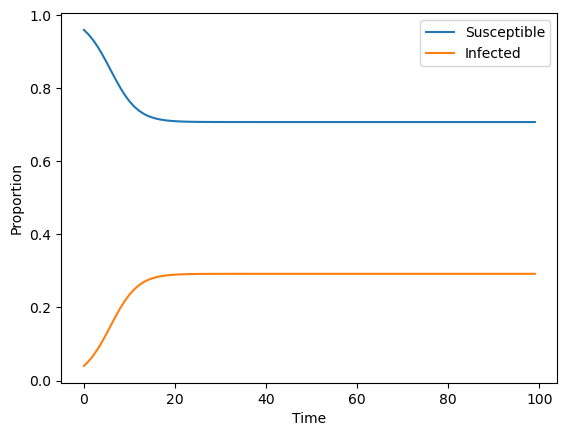

In [18]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

# 参数设置
N = 100  # 总节点数
D_ratio = 0.6  # 目的地节点比例
R_ratio = 1 - D_ratio  # 居住节点比例
R_count = int(R_ratio * N)  # 居住节点数
D_count = N - R_count  # 目的地节点数
P = 1000  # 总人口
beta = 0.1  # 感染率
mu = 0.1  # 恢复率
p = 0.1  # 移动概率
steps = 100  # 模拟时间步数

# # 初始化网络
# G = nx.watts_strogatz_graph(N, 4, 0.1)
# W = nx.adjacency_matrix(G).todense()

adj_matrix = np.random.rand(N, N)  # 随机生成邻接矩阵
np.fill_diagonal(adj_matrix, 0)  # 对角线元素为0
W = adj_matrix / np.sum(adj_matrix, axis=1, keepdims=True)  # 归一化邻接矩阵

# 计算C矩阵
C = np.zeros((N, N))
for i in range(N):
    if np.sum(W[i, :]) > 0:
        C[i, :] = W[i, :] / np.sum(W[i, :])

# 随机分配人口到居住节点
n = np.zeros(N)
for i in range(R_count):
    n[i] = P / R_count

# 初始感染
rho = np.zeros(N)
initial_infected = random.sample(range(R_count), int(1 * R_count))
for i in initial_infected:
    rho[i] = 0.1

# 计算从节点j移动到节点i的人数矩阵
def get_n_k_to_j(n, p, C):
    N = len(n)
    n_k_to_j = np.zeros((N, N))
    for j in range(N):
        for k in range(N):
            if k == j:
                n_k_to_j[k, j] = (1 - p) * n[j]
            else:
                n_k_to_j[k, j] = p * C[k, j] * n[k]
    return n_k_to_j

# 存储结果
rho_history = np.zeros((steps, N))

# 模拟过程
for t in range(steps):
    rho_history[t] = rho

    new_rho = np.zeros(N)
    
    n_k_to_j = get_n_k_to_j(n, p, C)
    
    for i in range(R_count):
        # 居住节点感染概率
        Ri_t = 1 - (1 - beta) ** ((1 - p) * 4 * rho[i] + p * np.sum([C[j, i] * 4 * rho[j] for j in range(R_count)]))

        # 目的地感染概率
        Di_t = []
        for j in range(D_count):
            nj_inflow = np.sum([n_k_to_j[k, j] * rho[k] for k in range(N)])
            Di_t.append(1 - (1 - beta) ** nj_inflow)
        
        # 健康个体被感染的概率
        Pi_t = (1 - p) * Ri_t + p * np.sum([C[i, j] * Di_t[j] for j in range(D_count)]) + p * np.sum([C[i, j] * Ri_t for j in range(R_count)])

        new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_t
    
    rho = new_rho

# 计算平均感染比例和健康比例
I_avg = np.mean(rho_history, axis=1)
S_avg = 1 - I_avg

# 绘图
plt.plot(range(steps), S_avg, label='Susceptible')
plt.plot(range(steps), I_avg, label='Infected')
plt.xlabel('Time')
plt.ylabel('Proportion')
plt.legend()
plt.show()


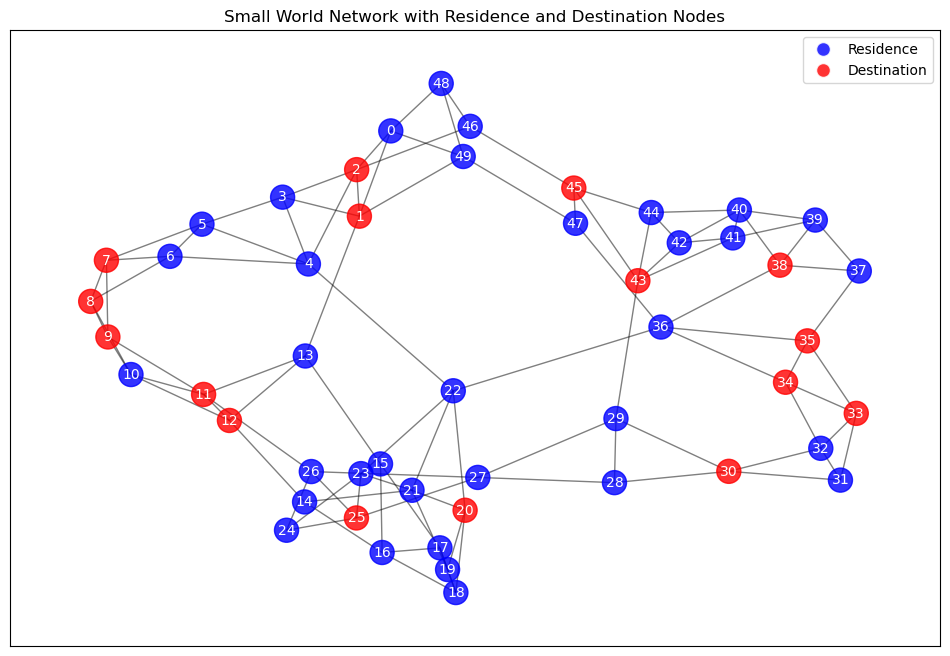

In [34]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# 设置随机种子以确保结果可复现
np.random.seed(42)

# 生成50个节点的小世界网络，平均度为4，重连概率为0.1
N = 50
k = 4
p = 0.1
G = nx.watts_strogatz_graph(N, k, p)

# 将30个节点设为Residence，20个节点设为Destination
residence_count = 30
destination_count = 20

# 随机分配节点类型
node_types = np.random.choice(['Residence', 'Destination'], size=N, p=[0.6, 0.4])

# 为节点添加类型属性
for i in range(N):
    G.nodes[i]['type'] = node_types[i]

# 绘制网络
pos = nx.spring_layout(G)  # 使用spring layout绘制网络

# 设置颜色映射
colors = {'Residence': 'blue', 'Destination': 'red'}
node_colors = [colors[G.nodes[i]['type']] for i in G.nodes]

# 绘制节点和边
plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=300, alpha=0.8)
nx.draw_networkx_edges(G, pos, alpha=0.5)
nx.draw_networkx_labels(G, pos, font_size=10, font_color="white")

# 添加图例
legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label='Residence',
                              markersize=10, markerfacecolor='blue', alpha=0.8),
                   plt.Line2D([0], [0], marker='o', color='w', label='Destination',
                              markersize=10, markerfacecolor='red', alpha=0.8)]
plt.legend(handles=legend_elements, loc='best')

plt.title("Small World Network with Residence and Destination Nodes")
plt.show()


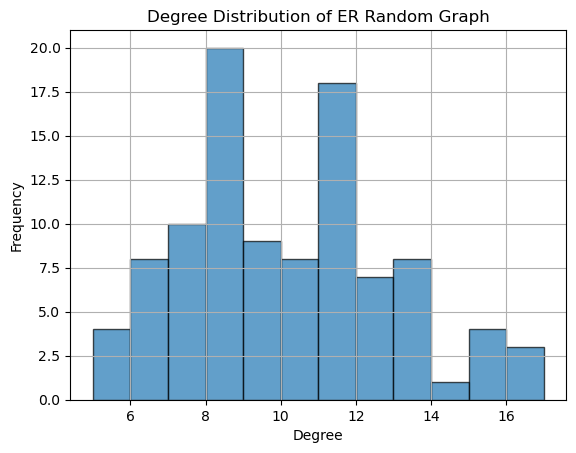

In [32]:
# 为了绘制一个有100个节点的ER随机图（Erdős-Rényi随机图）并展示其度分布图，我们可以使用Python的NetworkX库来生成随机图，并使用Matplotlib来绘制度分布图。
import networkx as nx
import matplotlib.pyplot as plt

# 定义节点数和边的连接概率
n = 100  # 节点数
p = 0.1  # 边的连接概率

# 生成ER随机图
G = nx.erdos_renyi_graph(n, p)

# 计算每个节点的度
degrees = [G.degree(n) for n in G.nodes()]

# 绘制度分布图
plt.hist(degrees, bins=range(min(degrees), max(degrees) + 1), edgecolor='black', alpha=0.7)
plt.xlabel('Degree')
plt.ylabel('Frequency')
plt.title('Degree Distribution of ER Random Graph')
plt.grid(True)
plt.show()
